# 44 - PBMC-68k: a second single-cell cohort with two rare-cluster forget sets

PBMC-33k contributes one rare forget set of 30 megakaryocytes (cluster 13). This notebook repeats the
whole protocol on the 68k PBMC set of Zheng et al. (2017), a second donor processed with the same
recipe as notebook 01 (QC, 2,000 highly variable genes, PCA, Leiden at resolution 0.5) and trained
with the notebook 02 recipe (`scripts/train_cohort.py`). Two rare clusters are the forget sets, each
with 40 percent of its cells held out of training so that within-type negatives exist by design.

**Cluster 9, megakaryocytes (178 cells; 107 forget, 71 held out).** PPBP, PF4 and GP9 in nearly
every cell. The published labels of Zheng et al. call these cells CD34+ because their label set
has no megakaryocyte class. This is the direct replicate of PBMC-33k cluster 13.

**Cluster 8, plasmacytoid dendritic cells (503 cells; 302 forget, 201 held out).** GZMB, MZB1,
LILRA4 and CLEC4C; the cluster also absorbs some B and CD34+ cells at this resolution, so it is a
larger and less pure rare cluster than the megakaryocytes.

For each forget set the pipeline is the paper's: one baseline (seed 42), eight clean retrains on the
retain split only (seeds 42 to 49; 42 is the audit reference), seven post-hoc methods at their PBMC-33k settings, three seeds
each, all descending from the baseline. Two matched-negative sets, cross-type (ten nearest held-out
cells of other clusters per forget cell in the baseline's latent space) and within-type (the held-out
cells of the forget cluster), each with its own attacker trained on the baseline and applied to every
checkpoint in one CPU pass (`scripts/score_pbmc68k.py`). The audit is the reference likelihood ratio
against clean retrain seed 42, with the other seven seeds giving the range a retrained model itself scores.

The two questions are the paper's. Does the cross-type protocol measure biology here as well
(retrained models above chance), and does within-type matching remove it? And do the post-hoc
methods reach the clean retrains' level on a forget set three to ten times the size of cluster 13?

In [1]:
import sys
sys.path.insert(0, '../src')

import json
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from pathlib import Path

import canonical as C

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
OUT = Path('../outputs/pbmc68k')
FS = {'mk': 'cluster 9, megakaryocytes', 'pdc': 'cluster 8, plasmacytoid dendritic cells'}
NAMES = {'baseline': 'Baseline', 'retrain': 'Clean retrain', 'retain_finetune': 'Retain-only fine-tune',
         'gradient_ascent': 'Gradient ascent + fine-tune', 'ssd': 'SSD', 'scrub': 'SCRUB', 'fisher': 'Fisher scrubbing',
         'contrastive': 'Contrastive latent', 'extragradient': 'Extra-gradient (lambda=10)', 'long_finetune': 'Retain-only fine-tune, 200 epochs'}

## The cohort and the two forget clusters

In [2]:
adata = sc.read_h5ad('../data/pbmc68k_processed.h5ad')
sizes = adata.obs['leiden'].value_counts().sort_index()
comp = pd.crosstab(adata.obs['leiden'], adata.obs['published_label'])
print(f'{adata.n_obs:,} cells x {adata.n_vars:,} genes; {len(sizes)} Leiden clusters')
comp.loc[['9', '8']].T[lambda d: d.sum(1) > 0]

68,512 cells x 2,000 genes; 10 Leiden clusters


leiden,9,8
published_label,,
CD4+ T Helper2,0,21
CD4+/CD25 T Reg,0,3
CD4+/CD45RA+/CD25- Naive T,0,9
CD8+ Cytotoxic T,0,2
CD8+/CD45RA+ Naive Cytotoxic,1,11
CD14+ Monocyte,0,1
CD19+ B,0,143
CD34+,177,72
CD56+ NK,0,1


In [3]:
MARKERS = {'9': ['PPBP', 'PF4', 'GP9', 'ITGA2B'], '8': ['GZMB', 'MZB1', 'LILRA4', 'CLEC4C', 'CD79A', 'CD34']}
rows = []
for cl, genes in MARKERS.items():
    genes = [g for g in genes if g in adata.var_names]
    inside = adata[adata.obs['leiden'] == cl][:, genes].X.toarray()
    outside = adata[adata.obs['leiden'] != cl][:, genes].X.toarray()
    for g, i, o in zip(genes, inside.T, outside.T):
        rows.append({'cluster': cl, 'gene': g, 'fraction expressing, cluster': (i > 0).mean(), 'fraction expressing, rest': (o > 0).mean(),
                     'mean log expression, cluster': i.mean(), 'mean log expression, rest': o.mean()})
pd.DataFrame(rows).set_index(['cluster', 'gene']).round(3)

fraction expressing, cluster  fraction expressing, rest  mean log expression, cluster  mean log expression, rest
cluster gene                                                                                                                    
9       PPBP                           1.000                      0.006                         5.852                      0.015
        PF4                            0.989                      0.002                         4.727                      0.005
        GP9                            0.899                      0.001                         3.268                      0.002
        ITGA2B                         0.798                      0.001                         2.699                      0.002
8       GZMB                           0.656                      0.149                         2.503                      0.477
        MZB1                           0.696                      0.011                         2.194                      0.024
        LILRA4                         0.412                      0.002                         1.153                      0.003
        CLEC4C                         0.157                      0.000                         0.389                      0.001
        CD79A                          0.217                      0.073                         0.600                      0.217

In [4]:
split_rows = []
for fs, label in FS.items():
    s = C.pbmc68k_split(fs)
    split_rows.append({'forget set': label, 'cluster size': int(sizes[s['forget_cluster']]), 'forget (trained on)': s['n_forget'],
                       'within-type held out': s['n_within_type_unseen'], 'retain': s['n_retain'], 'held out (all)': s['n_unseen'],
                       'cross-type negatives': C.pbmc68k_n_matched(fs), 'forget share of training (%)': round(100 * s['n_forget'] / (s['n_forget'] + s['n_retain']), 2)})
pd.DataFrame(split_rows).set_index('forget set')

,cluster size,forget (trained on),within-type held out,retain,held out (all),cross-type negatives,forget share of training (%)
forget set,,,,,,,
"cluster 9, megakaryocytes",178,107,71,57958,10447,143,0.18
"cluster 8, plasmacytoid dendritic cells",503,302,201,57763,10447,445,0.52


## Results

Advantage is 2|AUC - 0.5| with a nested bootstrap interval over seeds and cells for the transferred
cross-type attacker. `diff CI` is the nested bootstrap interval of the method's advantage minus the
clean retrains'. `audit` is the reference likelihood-ratio AUC against clean retrain seed 42 (near 1
means the forget cells are fitted as the baseline fits them; inside the retrained band means fitted as
a retrained model fits them; near 0 means fitted worse than any retrained model). The per-cell columns
are a logistic regression on standardized features refit on each checkpoint against the within-type
negatives and scored out of fold (20 fold splits), compared with the arm of eight clean retrains on the
cells every checkpoint shares (`scripts/percell_paired_test.py`; outer bootstrap over seeds, inner over the
shared cells). A method is at the retrained level per cell when the upper end of the paired interval lies
below a margin of half the baseline's excess, fixed before these scores existed; identifiable when the lower
end lies above zero; not resolved otherwise. Each checkpoint's own label-permutation null (1,000
permutations) is shown as the instrument's resolution, never as a threshold; the paper's raw-feature MLP reads little beyond the
reconstruction term and scored the baseline at 0.449 out of fold where this instrument finds 0.69
(`scripts/check_pbmc68k_extremes.py`, `check_feature_groups.py`). The transferred within-type attacker
appears in the per-seed detail only. Negative ELBO is per cell, lower is a better fit. ELBO, marker
correlation and ARI are the utility metrics on the held-out cells.

In [5]:
def table(fs):
    frames = []
    for kind in ('cross',):
        S = C.pbmc68k_summary(fs, kind)
        d = pd.DataFrame({NAMES[m]: {'seeds': r['n_seeds'], f'AUC {kind}': r['auc'], f'adv {kind}': r['mean'],
                                     f'adv CI {kind}': f"[{r['ci_low']:.3f}, {r['ci_high']:.3f}]",
                                     f'diff CI {kind}': '--' if r['diff_ci'] is None else f"[{r['diff_ci'][0]:.3f}, {r['diff_ci'][1]:.3f}]",
                                     f'audit {kind}': r['audit']} for m, r in S.items()}).T
        frames.append(d)
    PC = C.pbmc68k_refit_std(fs, 'within'); RES = C.pbmc68k_results(fs)['per_checkpoint']; PP = C.pbmc68k_percell_paired(fs, 'within')['arms']
    def nci(m, key):
        v = RES[m].get(key)
        return f"[{v['nested_ci_low']:.3f}, {v['nested_ci_high']:.3f}]" if v else '--'
    frames.append(pd.DataFrame({NAMES[m]: {'audit cross nested 95% CI': nci(m, 'audit_cross_nested'),
                                          'per-cell AUC (refit, within)': PP[m]['mean'], 'per-cell nested 95% CI': '[{:.3f}, {:.3f}]'.format(*PP[m]['nested_ci']),
                                          'per-cell AUC per seed': ', '.join(f'{a:.3f}' for a in PP[m]['per_seed_auc']),
                                          'per-cell advantage': r['advantage'],
                                          'paired diff from retrains': PP[m].get('diff', np.nan),
                                          'paired diff 95% CI': '[{:.3f}, {:.3f}]'.format(*PP[m]['diff_ci']) if 'diff_ci' in PP[m] else '--',
                                          'per-cell verdict': PP[m].get('verdict', 'reference'),
                                          'own permutation null p97.5': ', '.join(f'{x:.3f}' for x in PP[m]['perm_null_p975'])} for m, r in PC.items()}).T)
    S = C.pbmc68k_summary(fs, 'cross')
    fit = pd.DataFrame({NAMES[m]: {'forget negELBO': r['forget_neg_elbo'], 'within-type negELBO': r['within_neg_elbo'], 'cross-type negELBO': r['cross_neg_elbo'],
                                   'ELBO': r['elbo'], 'marker r': r['marker_r'], 'ARI': r['ari']} for m, r in S.items()}).T
    out = pd.concat(frames + [fit], axis=1)
    out = out.loc[:, ~out.columns.duplicated()]
    return out

def context(fs):
    d = C.pbmc68k_results(fs)
    for kind in ('cross', 'within'):
        thr = C.pbmc68k_threshold(fs, kind); band = C.pbmc68k_audit_band(fs, kind); nf = C.pbmc68k_null_floor(fs, kind)
        print(f"{fs} / {kind} (transferred attacker): retrains' nested CI upper {thr:.3f}; retrained-vs-retrained audit band {band[0]:.2f} to {band[1]:.2f}; "
              f"permutation null of the estimator {nf['mean']:.3f} [{nf['ci_low']:.3f}, {nf['ci_high']:.3f}]")
    P = C.pbmc68k_percell_paired(fs, 'within'); A = P['arms']; nl = C.percell_refit_null(fs)
    print(f"{fs} / per-cell (standardized logistic refit, within-type, out of fold): baseline {A['baseline']['mean']:.3f}, retrains "
          f"{P['retrain_range'][0]:.3f} to {P['retrain_range'][1]:.3f} (arm mean {P['retrain_mean']:.3f}); paired non-inferiority margin "
          f"{P['margin']:.3f} (half the baseline's excess); each checkpoint's own label-permutation null has its 97.5th percentile at "
          f"{nl['p975_range'][0]:.3f} to {nl['p975_range'][1]:.3f}")

### Cluster 9, megakaryocytes

In [6]:
context('mk')
table('mk').round(3)

mk / cross (transferred attacker): retrains' nested CI upper 0.985; retrained-vs-retrained audit band 0.07 to 0.92; permutation null of the estimator 0.060 [0.002, 0.168]
mk / within (transferred attacker): retrains' nested CI upper 0.117; retrained-vs-retrained audit band 0.47 to 0.55; permutation null of the estimator 0.070 [0.003, 0.191]
mk / per-cell (standardized logistic refit, within-type, out of fold): baseline 0.683, retrains 0.472 to 0.538 (arm mean 0.515); paired non-inferiority margin 0.084 (half the baseline's excess); each checkpoint's own label-permutation null has its 97.5th percentile at 0.590 to 0.606


,seeds,AUC cross,adv cross,adv CI cross,diff CI cross,audit cross,audit cross nested 95% CI,"per-cell AUC (refit, within)",per-cell nested 95% CI,per-cell AUC per seed,per-cell advantage,paired diff from retrains,paired diff 95% CI,per-cell verdict,own permutation null p97.5,forget negELBO,within-type negELBO,cross-type negELBO,ELBO,marker r,ARI
Baseline,1,0.965166,0.930331,"[0.873, 0.976]",--,1.0,"[1.000, 1.000]",0.683447,"[0.606, 0.757]",0.683,0.366895,0.168224,"[0.085, 0.247]",more identifiable than retrained,0.599,488.345,521.696,524.659,484.495,0.762,0.474
Clean retrain,8,0.011486,0.977028,"[0.968, 0.985]",--,0.523712,"[0.288, 0.749]",0.515223,"[0.455, 0.575]","0.523, 0.507, 0.472, 0.538, 0.530, 0.538, 0.51...",0.063491,NaN,--,reference,"0.599, 0.594, 0.605, 0.598, 0.603, 0.605, 0.59...",1036.999,1035.348,525.601,488.005,0.761,0.482
Retain-only fine-tune,3,0.76117,0.522341,"[0.424, 0.613]","[-0.555, -0.362]",1.0,"[1.000, 1.000]",0.556367,"[0.484, 0.626]","0.542, 0.563, 0.564",0.112733,0.041143,"[-0.025, 0.108]",not resolved,"0.595, 0.597, 0.592",668.062,665.127,524.155,484.959,0.761,0.443
Gradient ascent + fine-tune,3,0.88833,0.776659,"[0.722, 0.827]","[-0.255, -0.149]",1.0,"[1.000, 1.000]",0.581512,"[0.507, 0.654]","0.568, 0.606, 0.570",0.163025,0.066289,"[-0.005, 0.137]",not resolved,"0.601, 0.601, 0.593",614.079,619.303,524.076,484.678,0.762,0.469
SSD,3,0.806679,0.613359,"[0.536, 0.687]","[-0.440, -0.291]",1.0,"[1.000, 1.000]",0.646972,"[0.572, 0.721]","0.664, 0.635, 0.641",0.293945,0.131749,"[0.057, 0.204]",more identifiable than retrained,"0.601, 0.604, 0.595",608.633,614.412,523.743,484.842,0.761,0.457
SCRUB,3,0.854672,0.709344,"[0.562, 0.824]","[-0.416, -0.153]",0.99634,"[0.987, 1.000]",0.601373,"[0.528, 0.672]","0.596, 0.609, 0.598",0.202747,0.08615,"[0.018, 0.152]",more identifiable than retrained,"0.595, 0.600, 0.601",613.323,615.451,524.210,484.883,0.762,0.470
Contrastive latent,3,0.095266,0.809468,"[0.711, 0.891]","[-0.270, -0.086]",0.966603,"[0.939, 0.988]",0.558398,"[0.482, 0.634]","0.549, 0.562, 0.564",0.118814,0.043175,"[-0.026, 0.110]",not resolved,"0.598, 0.602, 0.600",733.012,739.902,523.990,485.948,0.761,0.480
Fisher scrubbing,3,0.400366,0.199268,"[0.098, 0.306]","[-0.877, -0.667]",0.642311,"[0.574, 0.708]",0.602745,"[0.527, 0.676]","0.622, 0.595, 0.591",0.205489,0.087521,"[0.017, 0.159]",more identifiable than retrained,"0.594, 0.595, 0.595",1024.338,938.576,523.889,486.764,0.762,0.435
Extra-gradient (lambda=10),3,0.568677,0.137355,"[0.031, 0.330]","[-0.947, -0.648]",0.999107,"[0.998, 1.000]",0.876679,"[0.813, 0.931]","0.840, 0.914, 0.877",0.753359,0.361456,"[0.285, 0.438]",more identifiable than retrained,"0.595, 0.598, 0.598",477.744,591.078,527.207,486.145,0.762,0.474
"Retain-only fine-tune, 200 epochs",3,0.352025,0.29595,"[0.189, 0.406]","[-0.787, -0.571]",0.999913,"[1.000, 1.000]",0.523529,"[0.452, 0.594]","0.526, 0.539, 0.506",0.065706,0.008306,"[-0.062, 0.080]",at the retrained level,"0.600, 0.599, 0.606",799.271,795.303,528.396,486.683,0.756,0.438


### Cluster 8, plasmacytoid dendritic cells

In [7]:
context('pdc')
table('pdc').round(3)

pdc / cross (transferred attacker): retrains' nested CI upper 0.571; retrained-vs-retrained audit band 0.29 to 0.53; permutation null of the estimator 0.034 [0.001, 0.096]
pdc / within (transferred attacker): retrains' nested CI upper 0.067; retrained-vs-retrained audit band 0.49 to 0.53; permutation null of the estimator 0.042 [0.002, 0.119]
pdc / per-cell (standardized logistic refit, within-type, out of fold): baseline 0.603, retrains 0.450 to 0.503 (arm mean 0.487); paired non-inferiority margin 0.058 (half the baseline's excess); each checkpoint's own label-permutation null has its 97.5th percentile at 0.555 to 0.563


,seeds,AUC cross,adv cross,adv CI cross,diff CI cross,audit cross,audit cross nested 95% CI,"per-cell AUC (refit, within)",per-cell nested 95% CI,per-cell AUC per seed,per-cell advantage,paired diff from retrains,paired diff 95% CI,per-cell verdict,own permutation null p97.5,forget negELBO,within-type negELBO,cross-type negELBO,ELBO,marker r,ARI
Baseline,1,0.580579,0.161158,"[0.077, 0.244]",--,0.99933,"[0.998, 1.000]",0.603488,"[0.555, 0.650]",0.603,0.206977,0.116965,"[0.075, 0.159]",more identifiable than retrained,0.559,498.401,513.455,472.134,484.405,0.762,0.474
Clean retrain,8,0.228783,0.542433,"[0.514, 0.571]",--,0.411538,"[0.339, 0.461]",0.486523,"[0.450, 0.523]","0.493, 0.450, 0.477, 0.491, 0.503, 0.489, 0.49...",0.043088,NaN,--,reference,"0.562, 0.560, 0.558, 0.561, 0.559, 0.560, 0.55...",635.693,630.216,472.244,486.700,0.756,0.470
Retain-only fine-tune,3,0.450088,0.099824,"[0.052, 0.148]","[-0.496, -0.385]",0.995037,"[0.993, 0.997]",0.548084,"[0.502, 0.594]","0.558, 0.544, 0.542",0.096168,0.06156,"[0.022, 0.102]",more identifiable than retrained,"0.562, 0.558, 0.557",548.162,551.102,470.961,484.634,0.760,0.468
Gradient ascent + fine-tune,3,0.479711,0.040578,"[0.016, 0.091]","[-0.538, -0.443]",0.997341,"[0.996, 0.999]",0.565919,"[0.518, 0.613]","0.584, 0.550, 0.564",0.131838,0.079395,"[0.037, 0.124]",more identifiable than retrained,"0.558, 0.561, 0.555",536.438,541.695,471.193,484.472,0.760,0.491
SSD,3,0.453362,0.093276,"[0.041, 0.152]","[-0.509, -0.384]",0.999122,"[0.999, 1.000]",0.57341,"[0.526, 0.619]","0.582, 0.560, 0.579",0.146821,0.086887,"[0.044, 0.129]",more identifiable than retrained,"0.561, 0.562, 0.561",530.695,535.971,471.749,484.576,0.761,0.451
SCRUB,3,0.517459,0.034918,"[0.014, 0.089]","[-0.539, -0.447]",0.998623,"[0.998, 0.999]",0.570088,"[0.516, 0.621]","0.540, 0.568, 0.602",0.140176,0.083565,"[0.035, 0.133]",more identifiable than retrained,"0.558, 0.562, 0.562",525.017,532.808,471.458,484.423,0.762,0.475
Contrastive latent,3,0.055551,0.888898,"[0.860, 0.914]","[0.307, 0.385]",0.010269,"[0.000, 0.023]",0.631596,"[0.585, 0.677]","0.632, 0.633, 0.630",0.263192,0.145072,"[0.097, 0.192]",more identifiable than retrained,"0.556, 0.560, 0.559",716.934,697.610,471.849,487.754,0.760,0.441
Fisher scrubbing,3,0.330419,0.339162,"[0.282, 0.397]","[-0.268, -0.140]",0.484275,"[0.422, 0.545]",0.588609,"[0.542, 0.633]","0.593, 0.590, 0.583",0.177217,0.102085,"[0.059, 0.145]",more identifiable than retrained,"0.557, 0.561, 0.562",880.671,1016.441,471.826,493.963,0.761,0.453
Extra-gradient (lambda=10),3,0.417194,0.165613,"[0.098, 0.233]","[-0.452, -0.302]",0.930493,"[0.838, 0.991]",0.769141,"[0.697, 0.835]","0.776, 0.828, 0.703",0.538281,0.282617,"[0.208, 0.355]",more identifiable than retrained,"0.557, 0.559, 0.561",482.117,549.994,473.514,486.300,0.762,0.481


## Per-seed detail

In [8]:
def per_seed(fs):
    d = C.pbmc68k_results(fs)['per_checkpoint']
    rows = []
    for m, v in d.items():
        for r in v['per_seed']:
            rows.append({'method': NAMES[m], **{k: r[k] for k in ('seed', 'attacker_cross', 'attacker_within', 'audit_cross', 'audit_within',
                                                                 'forget_neg_elbo', 'within_neg_elbo', 'cross_neg_elbo', 'elbo', 'marker_r', 'ari')}})
    return pd.DataFrame(rows).set_index(['method', 'seed']).round(3)
per_seed('mk')

attacker_cross  attacker_within  audit_cross  audit_within  forget_neg_elbo  within_neg_elbo  cross_neg_elbo     elbo  marker_r    ari
method                            seed                                                                                                                                           
Baseline                          seed42            0.965            0.597        1.000         0.575          488.345          521.696         524.659  484.495     0.762  0.474
Clean retrain                     seed_42           0.012            0.467        0.500         0.500         1031.745         1028.846         525.769  487.742     0.763  0.475
                                  seed_43           0.012            0.485        0.500         0.540         1033.892         1033.202         524.584  488.036     0.765  0.484
                                  seed_44           0.012            0.492        0.537         0.536         1029.804         1030.124         525.832  488.237     0.759  0.493
                                  seed_45           0.011            0.498        0.763         0.539         1019.100         1019.178         526.803  488.145     0.758  0.444
                                  seed_46           0.007            0.508        0.069         0.547         1106.320         1108.825         524.962  488.022     0.763  0.511
                                  seed_47           0.011            0.500        0.820         0.484         1008.205         1004.224         524.830  487.468     0.765  0.502
                                  seed_48           0.010            0.485        0.085         0.510         1085.757         1083.296         525.590  488.774     0.759  0.474
                                  seed_49           0.017            0.483        0.916         0.471          981.172          975.088         526.442  487.614     0.760  0.475
Retain-only fine-tune             123               0.723            0.429        1.000         0.492          681.239          681.113         524.642  485.128     0.761  0.480
                                  42                0.767            0.432        1.000         0.480          670.131          664.887         524.286  484.883     0.760  0.431
                                  456               0.793            0.434        1.000         0.487          652.817          649.381         523.537  484.866     0.763  0.419
Gradient ascent + fine-tune       123               0.879            0.477        1.000         0.512          623.159          628.677         524.143  484.689     0.761  0.471
                                  42                0.902            0.471        1.000         0.509          606.274          610.117         524.112  484.663     0.762  0.431
                                  456               0.884            0.478        1.000         0.514          612.805          619.116         523.975  484.682     0.763  0.505
Fisher scrubbing                  123               0.372            0.457        0.589         0.475         1108.138          997.579         524.015  487.080     0.760  0.428
                                  42                0.405            0.477        0.663         0.486          963.388          917.429         523.857  486.705     0.763  0.438
                                  456               0.424            0.455        0.675         0.469         1001.489          900.718         523.796  486.508     0.762  0.439
SSD                               123               0.802            0.536        1.000         0.520          606.721          613.337         523.666  484.851     0.761  0.436
                                  42                0.831            0.508        1.000         0.514          608.527          613.667         523.750  484.816     0.762  0.442
                                  456               0.787            0.517        1.000         0.518          610.649         

In [9]:
per_seed('pdc')

attacker_cross  attacker_within  audit_cross  audit_within  forget_neg_elbo  within_neg_elbo  cross_neg_elbo     elbo  marker_r    ari
method                      seed                                                                                                                                           
Baseline                    seed42            0.581            0.442        0.999         0.613          498.401          513.455         472.134  484.405     0.762  0.474
Clean retrain               seed_42           0.237            0.498        0.500         0.500          632.336          626.443         471.951  485.939     0.761  0.448
                            seed_43           0.234            0.502        0.474         0.530          633.538          628.741         472.580  486.657     0.751  0.443
                            seed_44           0.228            0.495        0.314         0.521          639.052          634.707         472.489  487.019     0.756  0.493
                            seed_45           0.223            0.504        0.427         0.517          634.816          629.654         472.129  486.861     0.753  0.513
                            seed_46           0.220            0.501        0.286         0.505          639.869          634.376         471.609  486.585     0.758  0.508
                            seed_47           0.228            0.501        0.399         0.491          636.477          629.962         472.608  486.777     0.756  0.444
                            seed_48           0.226            0.501        0.364         0.498          637.915          632.345         472.637  487.277     0.757  0.484
                            seed_49           0.235            0.498        0.528         0.510          631.546          625.500         471.949  486.481     0.755  0.431
Retain-only fine-tune       123               0.445            0.476        0.996         0.559          549.152          552.400         470.885  484.606     0.760  0.440
                            42                0.455            0.476        0.994         0.555          546.227          549.170         470.781  484.640     0.760  0.475
                            456               0.451            0.478        0.995         0.557          549.106          551.735         471.217  484.656     0.760  0.490
Gradient ascent + fine-tune 123               0.479            0.470        0.998         0.572          536.237          541.683         471.474  484.494     0.761  0.484
                            42                0.479            0.473        0.997         0.568          537.610          542.655         470.973  484.510     0.759  0.498
                            456               0.481            0.473        0.998         0.571          535.466          540.746         471.131  484.412     0.761  0.492
Fisher scrubbing            123               0.317            0.474        0.423         0.547          983.173         1104.032         471.806  495.982     0.762  0.427
                            42                0.336            0.470        0.488         0.558          744.336          814.148         471.590  490.009     0.761  0.432
                            456               0.338            0.469        0.542         0.570          914.503         1131.143         472.082  495.899     0.760  0.499
SSD                         123               0.440            0.475        0.999         0.571          533.181          538.307         471.712  484.656     0.761  0.428
                            42                0.447            0.474        0.999         0.575          531.740          537.420         471.915  484.608     0.761  0.489
                            456               0.473            0.474        0.999         0.565          527.165          532.185         471.621  484.464     0.760  0.436
SCRUB                       123               0.527            0.470        0.999

## The forget cells on the calibration axis

Each point is one checkpoint. The horizontal axis is how well the model fits the forget cells; the
vertical axis is how well it fits the held-out cells of the same cluster, which the model never
trained on. Retrained models sit where the two are equal (they know neither set); the baseline
sits to the left (forget cells fitted better than their held-out siblings). A post-hoc method
succeeds only if it moves the forget cells to the retrained models' level without moving the
held-out siblings.

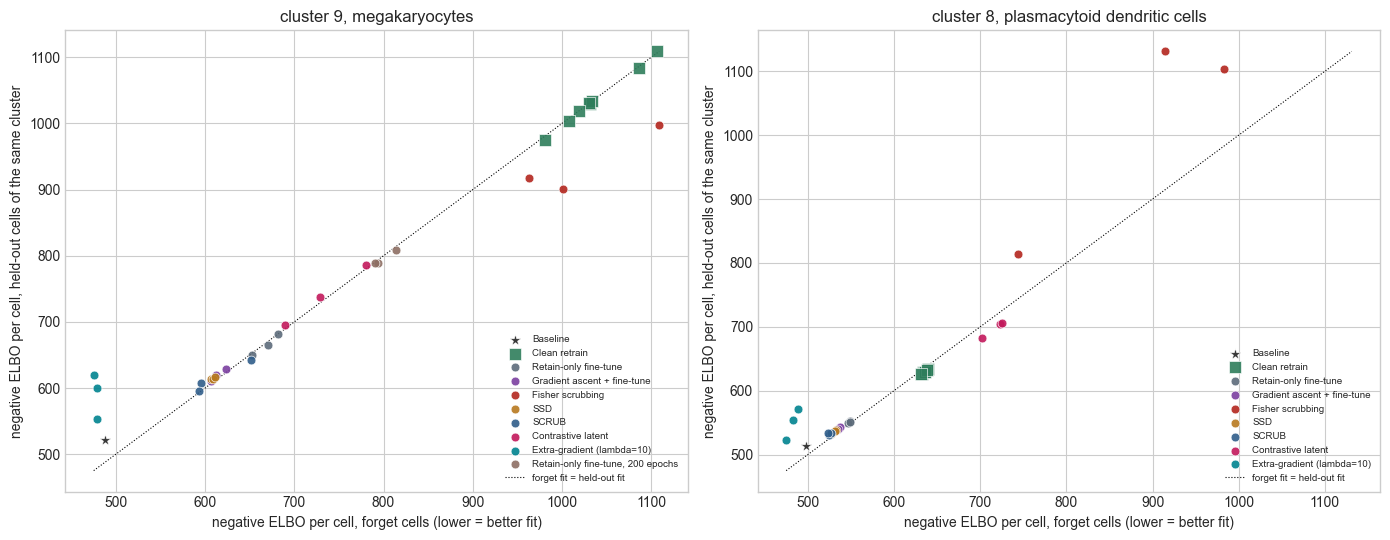

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
colors = {'baseline': '#222222', 'retrain': '#2E7D5B', 'retain_finetune': '#5C6B7A', 'gradient_ascent': '#7B3FA0', 'ssd': '#B7791F',
          'scrub': '#2F5D8A', 'fisher': '#B3261E', 'contrastive': '#C2185B', 'extragradient': '#00838F', 'long_finetune': '#8D6E63'}
for ax, fs in zip(axes, FS):
    d = C.pbmc68k_results(fs)['per_checkpoint']
    for m, v in d.items():
        xs = [r['forget_neg_elbo'] for r in v['per_seed']]; ys = [r['within_neg_elbo'] for r in v['per_seed']]
        ax.scatter(xs, ys, s=70 if m in ('baseline', 'retrain') else 40, color=colors[m], marker='s' if m == 'retrain' else ('*' if m == 'baseline' else 'o'),
                   label=NAMES[m], alpha=0.9, edgecolor='white', linewidth=0.5, zorder=3)
    lo = min(min(r['forget_neg_elbo'], r['within_neg_elbo']) for v in d.values() for r in v['per_seed'])
    hi = max(max(r['forget_neg_elbo'], r['within_neg_elbo']) for v in d.values() for r in v['per_seed'])
    ax.plot([lo, hi], [lo, hi], color='k', lw=0.8, ls=':', label='forget fit = held-out fit')
    ax.set_xlabel('negative ELBO per cell, forget cells (lower = better fit)'); ax.set_ylabel('negative ELBO per cell, held-out cells of the same cluster')
    ax.set_title(FS[fs])
    ax.legend(fontsize=7, loc='lower right')
plt.tight_layout()
plt.savefig(OUT / 'calibration_axis_68k.png', dpi=150, bbox_inches='tight')
plt.show()

## Side by side with PBMC-33k cluster 13

The same protocol on the first cohort, for the same quantities (canonical one-attacker CPU pass;
cluster 13 has 194 cross-type negatives and no within-type negatives beyond the five unseen
megakaryocytes, which is why the 68k splits hold 40 percent of each rare cluster out).

In [11]:
rows = [{'cohort / forget set': 'PBMC-33k cluster 13 (30 megakaryocytes)', 'negatives': 'cross (194)', 'baseline AUC': C.pbmc_auc('baseline'),
         'retrain AUC': C.pbmc_auc('retrain'), 'retrain advantage': C.pbmc_advantage('retrain')['mean'], 'threshold': C.pbmc_success_threshold(),
         'best post-hoc advantage': min(v['mean'] for k, v in C.pbmc_summary().items() if k not in ('baseline', 'retrain', 'retrain_leaky', 'dp_sgd'))}]
for fs, label in FS.items():
    for kind in ('cross', 'within'):
        S = C.pbmc68k_summary(fs, kind)
        rows.append({'cohort / forget set': f'PBMC-68k {label} ({C.pbmc68k_split(fs)["n_forget"]} cells)',
                     'negatives': f'{kind} ({C.pbmc68k_n_matched(fs) if kind == "cross" else C.pbmc68k_split(fs)["n_within_type_unseen"]})',
                     'baseline AUC': S['baseline']['auc'], 'retrain AUC': S['retrain']['auc'], 'retrain advantage': S['retrain']['mean'],
                     'threshold': C.pbmc68k_threshold(fs, kind),
                     'best post-hoc advantage': min(v['mean'] for k, v in S.items() if k not in ('baseline', 'retrain', 'long_finetune'))})
pd.DataFrame(rows).set_index(['cohort / forget set', 'negatives']).round(3)

baseline AUC  retrain AUC  retrain advantage  threshold  best post-hoc advantage
cohort / forget set                                negatives                                                                                     
PBMC-33k cluster 13 (30 megakaryocytes)            cross (194)          0.801        0.529              0.057      0.182                    0.111
PBMC-68k cluster 9, megakaryocytes (107 cells)     cross (143)          0.965        0.011              0.977      0.985                    0.137
                                                   within (71)          0.597        0.490              0.024      0.117                    0.026
PBMC-68k cluster 8, plasmacytoid dendritic cell... cross (445)          0.581        0.229              0.542      0.571                    0.035
                                                   within (201)         0.442        0.500              0.004      0.067                    0.028

## Out-of-fold refit attackers

The transferred attacker above is trained on the baseline and scored in-sample on the baseline. For the
baseline, the clean retrains, and the long fine-tune below, an attacker is also refit on each checkpoint's
own features and scored out of fold (stratified 5-fold, 20 fold splits; the refit control of the PBMC-33k
paper). This is the honest reading of how much per-cell membership signal each model carries under
within-type negatives, and of the type signal under cross-type negatives.

In [12]:
rows = []
for fs, label in FS.items():
    for kind in ('cross', 'within'):
        for m, r in C.pbmc68k_refit(fs, kind).items():
            rows.append({'forget set': label, 'negatives': kind, 'model': NAMES[m], 'seeds': r['n_seeds'], 'refit AUC (out of fold)': r['cv_auc_mean'],
                         'per-seed': ', '.join(f'{a:.3f}' for a in r['cv_auc_per_seed']), 'sd over fold splits': r['cv_auc_split_sd']})
pd.DataFrame(rows).set_index(['forget set', 'negatives', 'model']).round(3)

seeds  refit AUC (out of fold)                                           per-seed  sd over fold splits
forget set                              negatives model                                                                                                                                    
cluster 9, megakaryocytes               cross     Baseline                               1                    0.904                                              0.904                0.041
                                                  Clean retrain                          8                    0.963  0.960, 0.962, 0.963, 0.963, 0.976, 0.958, 0.97...                0.022
                                                  Retain-only fine-tune, 200 epochs      3                    0.803                                0.811, 0.805, 0.793                0.070
                                        within    Baseline                               1                    0.452                                              0.452                0.020
                                                  Clean retrain                          8                    0.496  0.498, 0.491, 0.493, 0.493, 0.491, 0.499, 0.49...                0.009
                                                  Retain-only fine-tune, 200 epochs      3                    0.506                                0.508, 0.508, 0.501                0.010
cluster 8, plasmacytoid dendritic cells cross     Baseline                               1                    0.658                                              0.658                0.037
                                                  Clean retrain                          8                    0.746  0.736, 0.741, 0.752, 0.746, 0.762, 0.747, 0.74...                0.022
                                        within    Baseline                               1                    0.473                                              0.473                0.011
                                                  Clean retrain                          8                    0.505  0.503, 0.504, 0.502, 0.508, 0.506, 0.506, 0.50...                0.007

## Long retain-only fine-tuning on the megakaryocytes

Notebook 42's experiment on this cohort (`scripts/long_finetune_pbmc68k.py`): 200 epochs of the methods'
own retain fine-tune from the baseline, three seeds, measured every five epochs. The retrained models fit
every megakaryocyte, trained on or held out, at the same level, because nothing in the retain set
resembles them; the baseline fits the ones it trained on better than their held-out siblings.

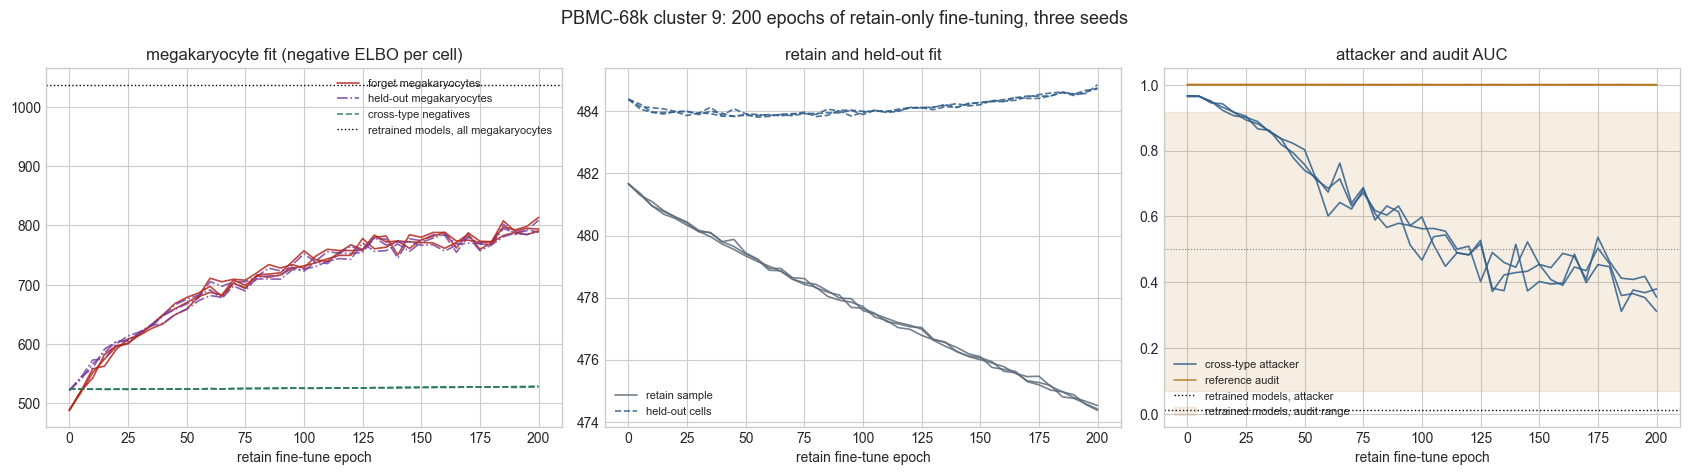

In [13]:
lf = C.pbmc68k_long_finetune()
lv = lf['levels']; H = {sd: pd.DataFrame(h) for sd, h in lf['history'].items()}
retr = {k: np.mean([v[k] for kk, v in lv.items() if kk.startswith('retrain_clean')]) for k in ('forget', 'within', 'cross', 'retain_sample', 'unseen')}
res_mk = C.pbmc68k_results('mk'); retr_auc = np.mean(res_mk['summary']['cross']['retrain']['per_seed_auc']); band = C.pbmc68k_audit_band('mk', 'cross')
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
first = list(H)[0]
for sd, d in H.items():
    lab = sd == first
    axes[0].plot(d.epoch, d.forget_neg_elbo, color='#B3261E', lw=1.2, alpha=0.85, label='forget megakaryocytes' if lab else None)
    axes[0].plot(d.epoch, d.within_neg_elbo, color='#7B3FA0', lw=1.2, alpha=0.85, ls='-.', label='held-out megakaryocytes' if lab else None)
    axes[0].plot(d.epoch, d.matched_neg_elbo, color='#2E7D5B', lw=1.2, alpha=0.85, ls='--', label='cross-type negatives' if lab else None)
    axes[1].plot(d.epoch, d.retain_neg_elbo, color='#5C6B7A', lw=1.2, alpha=0.85, label='retain sample' if lab else None)
    axes[1].plot(d.epoch, d.unseen_neg_elbo, color='#2F5D8A', lw=1.2, alpha=0.85, ls='--', label='held-out cells' if lab else None)
    axes[2].plot(d.epoch, d.mlp_auc, color='#2F5D8A', lw=1.2, alpha=0.85, label='cross-type attacker' if lab else None)
    axes[2].plot(d.epoch, d.lr_auc, color='#B7791F', lw=1.2, alpha=0.85, label='reference audit' if lab else None)
axes[0].axhline(retr['forget'], color='k', lw=1, ls=':', label='retrained models, all megakaryocytes')
axes[2].axhline(retr_auc, color='k', lw=1, ls=':', label='retrained models, attacker')
axes[2].axhspan(band[0], band[1], color='#B7791F', alpha=0.12, label='retrained models, audit range')
axes[2].axhline(0.5, color='grey', lw=0.8, ls=':')
axes[0].set_title('megakaryocyte fit (negative ELBO per cell)'); axes[1].set_title('retain and held-out fit'); axes[2].set_title('attacker and audit AUC')
for a in axes:
    a.set_xlabel('retain fine-tune epoch'); a.legend(fontsize=8)
plt.suptitle('PBMC-68k cluster 9: 200 epochs of retain-only fine-tuning, three seeds', fontsize=13)
plt.tight_layout()
plt.savefig(OUT / 'long_finetune_68k.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
rows = []
for sd, d in H.items():
    d = d.set_index('epoch')
    for e in (0, 10, 50, 100, 150, 200):
        rows.append({'seed': sd, 'epoch': e, **{c: d.loc[e, c] for c in ('forget_neg_elbo', 'within_neg_elbo', 'matched_neg_elbo', 'retain_neg_elbo', 'unseen_neg_elbo', 'mlp_auc', 'lr_auc')}})
tab = pd.DataFrame(rows).set_index(['seed', 'epoch']).round(3)
print('retrained models:', {k: round(v, 1) for k, v in retr.items()}, f'attacker {retr_auc:.3f}, audit range {band[0]:.2f} to {band[1]:.2f}')
tab

retrained models: {'forget': 1037.0, 'within': 1035.3, 'cross': 525.6, 'retain_sample': 481.8, 'unseen': 484.5} attacker 0.011, audit range 0.07 to 0.92


forget_neg_elbo  within_neg_elbo  matched_neg_elbo  retain_neg_elbo  unseen_neg_elbo  mlp_auc  lr_auc
seed epoch                                                                                                       
42   0              488.345          521.696           524.659          481.669          484.395    0.967     1.0
     10             552.196          566.518           523.939          480.961          483.979    0.949     1.0
     50             669.893          667.510           523.838          479.411          483.903    0.757     1.0
     100            727.972          722.553           525.567          477.581          483.902    0.598     1.0
     150            779.813          774.029           526.888          475.996          484.293    0.402     1.0
     200            793.698          788.370           527.655          474.519          484.761    0.380     1.0
123  0              488.345          521.696           524.659          481.669          484.395    0.966     1.0
     10             558.113          573.168           524.109          480.962          483.970    0.945     1.0
     50             658.992          658.373           524.698          479.343          483.874    0.802     1.0
     100            731.843          726.154           525.518          477.711          484.005    0.563     1.0
     150            775.722          771.437           527.305          476.062          484.276    0.455     1.0
     200            813.384          808.614           528.508          474.408          484.720    0.312     1.0
456  0              488.345          521.696           524.659          481.669          484.395    0.964     1.0
     10             542.975          559.873           523.822          481.097          484.121    0.951     1.0
     50             678.468          675.268           524.187          479.440          483.924    0.740     1.0
     100            757.129          751.852           525.370          477.655          483.966    0.467     1.0
     150            771.086          766.401           526.830          476.094          484.216    0.455     1.0
     200            790.730          788.925           529.027          474.365          484.862    0.355     1.0

In [15]:
# the epoch-200 models under every instrument of the one-pass scorer (both attackers, both audits, utility)
if 'long_finetune' in res_mk['per_checkpoint']:
    display(pd.DataFrame([{'seed': r['seed'], **{k: r[k] for k in ('attacker_cross', 'attacker_within', 'audit_cross', 'audit_within', 'forget_neg_elbo', 'within_neg_elbo', 'elbo', 'marker_r', 'ari')}}
                          for r in res_mk['per_checkpoint']['long_finetune']['per_seed']]).set_index('seed').round(3))

,attacker_cross,attacker_within,audit_cross,audit_within,forget_neg_elbo,within_neg_elbo,elbo,marker_r,ari
seed,,,,,,,,,
123,0.309,0.436,1.0,0.479,813.384,808.614,486.734,0.756,0.465
42,0.383,0.420,1.0,0.476,793.698,788.370,486.608,0.755,0.429
456,0.364,0.468,1.0,0.488,790.730,788.925,486.707,0.756,0.421


## Findings

The criterion is the adversary's: can the strongest attacker available tell the forget cells from held-out
cells of the same type any better on this model than on a model retrained without them? Each arm is compared
with the arm of eight clean retrains, paired on the cells every checkpoint shares, and passes only when the
upper end of the 95 percent interval of the difference lies below a margin fixed before the scores existed,
half the baseline's excess over the retrains (`scripts/percell_paired_test.py`). An interval that includes
zero but reaches past the margin is not resolved: the design, 107 + 71 and 302 + 201 cells, cannot tell such
a method from a retrained model or from one that removed less than half of the signal. Each checkpoint's own
label-permutation null is shown as the instrument's resolution, never as a threshold. Whether the model still
represents the type is reported beside the criterion, from the cross-type audit and the forget-cell median.

The first version of this notebook (2026-09-22, morning) passed most methods under the rule `per-cell AUC <=
max(retrains' max, null p97.5)`, with the reference arm scored under a different random state than the
methods and a noise-feature null that no script wrote; `PEER_REVIEW_ROUND7.md` records the three defects.

In [16]:
from IPython.display import Markdown
def findings(fs, label):
    P = C.pbmc68k_percell_paired(fs, 'within'); A = P['arms']; nl = C.percell_refit_null(fs)
    med = C.forget_fit_quantiles(f'pbmc68k_{fs}'); rm = list(med['retrain_median'].values())
    out = [f"**{label}.** Per-cell refit on the baseline {A['baseline']['mean']:.3f} (paired excess over the retrains "
           f"{A['baseline']['diff']:+.3f} [{A['baseline']['diff_ci'][0]:+.3f}, {A['baseline']['diff_ci'][1]:+.3f}]); eight retrains "
           f"{P['retrain_range'][0]:.3f} to {P['retrain_range'][1]:.3f}; margin {P['margin']:.3f}; each checkpoint's own null "
           f"reaches {nl['p975_range'][0]:.3f} to {nl['p975_range'][1]:.3f} at its 97.5th percentile. Retrained forget-cell medians "
           f"{min(rm):,.0f} to {max(rm):,.0f}.", '']
    for m in sorted((k for k in A if k not in ('retrain', 'baseline')), key=lambda k: A[k]['diff']):
        r = A[m]; meds = [x['forget_median'] for x in med['models'][m]]
        flag = '; more identifiable than the baseline' if r['more_identifiable_than_baseline'] else ''
        out.append(f"- {NAMES[m]}: {r['mean']:.3f}, difference {r['diff']:+.3f} [{r['diff_ci'][0]:+.3f}, {r['diff_ci'][1]:+.3f}], "
                   f"**{r['verdict']}**{flag} (Holm over the arms: {r['verdict_holm']}); against the baseline "
                   f"[{r['diff_vs_baseline_ci'][0]:+.3f}, {r['diff_vs_baseline_ci'][1]:+.3f}]; forget median {min(meds):,.0f} to {max(meds):,.0f}")
    return '\n'.join(out)
display(Markdown(findings('mk', 'Cluster 9, megakaryocytes')))
display(Markdown(findings('pdc', 'Cluster 8, plasmacytoid dendritic cells')))

**Cluster 9, megakaryocytes.** Per-cell refit on the baseline 0.683 (paired excess over the retrains +0.168 [+0.085, +0.247]); eight retrains 0.472 to 0.538; margin 0.084; each checkpoint's own null reaches 0.590 to 0.606 at its 97.5th percentile. Retrained forget-cell medians 1,014 to 1,154.

- Retain-only fine-tune, 200 epochs: 0.524, difference +0.008 [-0.062, +0.080], **at the retrained level** (Holm over the arms: not resolved); against the baseline [-0.240, -0.078]; forget median 820 to 846
- Retain-only fine-tune: 0.556, difference +0.041 [-0.025, +0.108], **not resolved** (Holm over the arms: not resolved); against the baseline [-0.190, -0.066]; forget median 665 to 697
- Contrastive latent: 0.558, difference +0.043 [-0.026, +0.110], **not resolved** (Holm over the arms: not resolved); against the baseline [-0.207, -0.042]; forget median 663 to 755
- Gradient ascent + fine-tune: 0.582, difference +0.066 [-0.005, +0.137], **not resolved** (Holm over the arms: not resolved); against the baseline [-0.155, -0.050]; forget median 615 to 634
- SCRUB: 0.601, difference +0.086 [+0.018, +0.152], **more identifiable than retrained** (Holm over the arms: not resolved); against the baseline [-0.137, -0.027]; forget median 572 to 622
- Fisher scrubbing: 0.603, difference +0.088 [+0.017, +0.159], **more identifiable than retrained** (Holm over the arms: not resolved); against the baseline [-0.143, -0.019]; forget median 814 to 831
- SSD: 0.647, difference +0.132 [+0.057, +0.204], **more identifiable than retrained** (Holm over the arms: more identifiable than retrained); against the baseline [-0.088, +0.015]; forget median 607 to 614
- Extra-gradient (lambda=10): 0.877, difference +0.361 [+0.285, +0.438], **more identifiable than retrained**; more identifiable than the baseline (Holm over the arms: more identifiable than retrained); against the baseline [+0.120, +0.269]; forget median 475 to 489

**Cluster 8, plasmacytoid dendritic cells.** Per-cell refit on the baseline 0.603 (paired excess over the retrains +0.117 [+0.075, +0.159]); eight retrains 0.450 to 0.503; margin 0.058; each checkpoint's own null reaches 0.555 to 0.563 at its 97.5th percentile. Retrained forget-cell medians 672 to 684.

- Retain-only fine-tune: 0.548, difference +0.062 [+0.022, +0.102], **more identifiable than retrained** (Holm over the arms: more identifiable than retrained); against the baseline [-0.086, -0.025]; forget median 580 to 585
- Gradient ascent + fine-tune: 0.566, difference +0.079 [+0.037, +0.124], **more identifiable than retrained** (Holm over the arms: more identifiable than retrained); against the baseline [-0.068, -0.006]; forget median 568 to 571
- SCRUB: 0.570, difference +0.084 [+0.035, +0.133], **more identifiable than retrained** (Holm over the arms: more identifiable than retrained); against the baseline [-0.071, +0.004]; forget median 555 to 557
- SSD: 0.573, difference +0.087 [+0.044, +0.129], **more identifiable than retrained** (Holm over the arms: more identifiable than retrained); against the baseline [-0.055, -0.005]; forget median 561 to 572
- Fisher scrubbing: 0.589, difference +0.102 [+0.059, +0.145], **more identifiable than retrained** (Holm over the arms: more identifiable than retrained); against the baseline [-0.046, +0.016]; forget median 697 to 812
- Contrastive latent: 0.632, difference +0.145 [+0.097, +0.192], **more identifiable than retrained** (Holm over the arms: more identifiable than retrained); against the baseline [-0.024, +0.081]; forget median 747 to 777
- Extra-gradient (lambda=10): 0.769, difference +0.283 [+0.208, +0.355], **more identifiable than retrained**; more identifiable than the baseline (Holm over the arms: more identifiable than retrained); against the baseline [+0.094, +0.237]; forget median 492 to 508